# Zadanie 9 Lista 1 - Rozwiązanie zadania
Zuzanna Sosnowska, 268483

In [9]:
import numpy as np
from scipy.stats import norm
import matplotlib.pyplot as plt
from typing import Union

### 1. Koszt reasekuracji polis z SU > 30

In [10]:
def reinsurance_cost(L: float, n: Union[int, list[int]], SU: Union[int, list], cost: float) -> float:
    if isinstance(n, int):
        n = [n]
    if not isinstance(SU, list):
        SU = [SU]
    if len(SU) != len(n):
        raise ValueError('SU and n must have same length')
    P = 0
    for i in range(len(n)):
        P += cost * n[i] * np.max([SU[i] - L, 0])
    return P

### 2. Obliczenie wartości oczekiwanej i II momentu dla zm. losowej $R = min(B, L)$

In [11]:
def expected_R(L: float, SU: float) -> float:
    if SU <= L:
        return SU / 2
    else:
        return L - L ** 2 / (2 * SU)


def expected_R2(L: float, SU: float) -> float:
    if SU <= L:
        return SU ** 2 / 3
    else:
        return L ** 2 - (2 * L ** 3) / (3 * SU)

### 3. Obliczenie wartości oczekiwanej i II momentu dla zmiennej losowej $Y = I \cdot R$

In [12]:
def expected_Y(L: float, SU: float, p: float) -> float:
    return p * expected_R(L = L, SU = SU)


def expected_Y2(L: float, SU: float, p: float) -> float:
    return p * expected_R2(L = L, SU = SU)


def Y_variance(L: float, SU: float, p: float) -> float:
    return expected_Y2(L = L, SU = SU, p = p) - (expected_Y(L = L, SU = SU, p = p)) ** 2

### 4. Obliczenie wartości oczekiwanej, wariancji i odchylenia standardowego dla portfolio

In [13]:
def expected_S(L: float, n: Union[int, list[int]], SU: Union[float, list], p: float) -> float:
    if isinstance(n, int):
        n = [n]
    if not isinstance(SU, list):
        SU = [SU]
    if len(SU) != len(n):
        print(len(SU), len(n))
        raise ValueError('SU and n must have same length')
    expected_value = 0
    for i in range(len(n)):
        expected_value += n[i] * expected_Y(L = L, SU = SU[i], p = p)
    return expected_value


def S_variance(L: float, n: Union[int, list[int]], SU: Union[float, list], p: float) -> float:
    if isinstance(n, int):
        n = [n]
    if not isinstance(SU, list):
        SU = [SU]
    if len(SU) != len(n):
        raise ValueError('SU and n must have same length')
    variance = 0
    for i in range(len(n)):
        variance += n[i] * Y_variance(L = L, SU = SU[i], p = p)
    return variance


def S_std(L: float, n: Union[int, list[int]], SU: Union[float, list], p: float) -> float:
    return np.sqrt(S_variance(L = L, n = n, SU = SU, p = p))

### 5. Obliczenie przybliżonej wartości prawdopodobieństwa, że koszty TU (wypłaty za szkody + koszty reasekuracji) przekroczą 82.5

Metoda ta zakłada, że suma wartości szkód dla i-tej polisy po standaryzacji będzie miała rozkład normalny.

In [14]:
def calculate_probability_approximation(
        value: float,
        L: float,
        n: Union[int, list[int]],
        SU: Union[float, list],
        p: float,
        cost: float
) -> float:
    mu = expected_S(L = L, n = n, SU = SU, p = p)
    std = S_std(L = L, n = n, SU = SU, p = p)
    premium = reinsurance_cost(L = L, SU = SU, n = n, cost = cost)
    q = (value - premium - mu) / std
    return 1 - norm.cdf(q)

### 6. Sprawdzenie wyników dla polis z zadania 8.

In [17]:
liczba_polis = [80, 35, 25, 15, 5]
wartosc_SU = [10, 20, 30, 50, 100]

pr_pozaru = 0.04
limit_odpowiedzialnosci = np.arange(10, 50, 0.1)
wartosc_prawdopodobienstwa = np.zeros_like(limit_odpowiedzialnosci)

wartosc = 82.5
koszt_reasekuracji = 0.025

for i in range(len(wartosc_prawdopodobienstwa)):
    prawdopodobienstwo = calculate_probability_approximation(
        value=wartosc,
        L=limit_odpowiedzialnosci[i],
        n=liczba_polis,
        SU=wartosc_SU,
        p=pr_pozaru,
        cost=koszt_reasekuracji
    )
    wartosc_prawdopodobienstwa[i] = prawdopodobienstwo

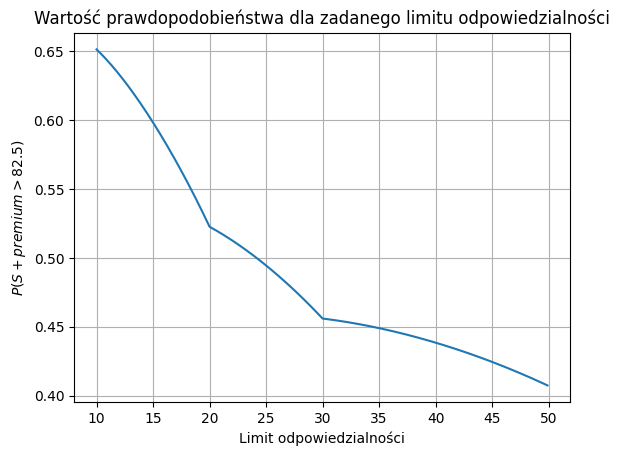

In [18]:
plt.plot(limit_odpowiedzialnosci, wartosc_prawdopodobienstwa)
plt.xlabel('Limit odpowiedzialności')
plt.ylabel(rf'$P(S + premium > {wartosc})$')
plt.grid(True)
plt.title('Wartość prawdopodobieństwa dla zadanego limitu odpowiedzialności')
plt.show()

Na podstawie wykresu można zauważyć, że w przedziale $(30, 50)$ wraz ze wzrostem limitu odpowiedzialności maleje prawdopodobieństwo, iż łączne koszty ponoszone przez TU (w tym składka reasekuracyjna) przekroczą wartość $82,5$. Oznacza to, że w celu minimalizacji tego ryzyka korzystne jest ustalenie limitu odpowiedzialności możliwie blisko górnej granicy rozważanego przedziału, tj. około $L = 50$.